# Лабораторная работа 2
## Кластерный анализ методом KMeans

Выполнил: Ларин Сергей Эдуардович, 563456

## Цель работы

Выделить группы городов со схожими экономическими показателями
методом KMeans. Выбрать число кластеров по графику локтя и среднему
силуэту. Объяснить различия между группами по их центрам.

## Данные

Исследуются показатели 48 городов за 1991 год.
Work характеризует число рабочих часов, Price является индексом цен,
Salary является индексом почасовой зарплаты после налогов и отчислений.
Для Price и Salary за 100 принят уровень Цюриха.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Разделителем столбцов в файле служит точка с запятой.
# Дробная часть чисел записана через запятую.
df = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",")

# City сохраняем для подписей. Расстояния считаем по трём показателям.
features = ["Work", "Price", "Salary"]

# Минус 9999 встречается в часах и зарплате.
# По смыслу показателей принимаем его за код отсутствующего значения.
df[features] = df[features].replace(-9999, np.nan)

# Находим города, у которых отсутствует хотя бы один показатель.
incomplete = df[features].isna().any(axis=1)
display(df.loc[incomplete, ["City", *features]])

# Сохраняем полный набор показателей для каждого оставшегося города.
cities = df.loc[~incomplete].copy().reset_index(drop=True)

print("Городов в файле:", len(df))
print("Городов для кластеризации:", len(cities))

,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN


Городов в файле: 48
Городов для кластеризации: 46


## Подготовка признаков

KMeans распределяет города по расстоянию до центров.
Рабочие часы и экономические индексы имеют разные масштабы.
Перед кластеризацией стандартизируем каждый показатель.
Исходные значения сохраним для интерпретации центров.

In [2]:
# Исходные значения понадобятся для объяснения групп.
X = cities[features].copy()

# Для каждого столбца вычитаем среднее и делим на стандартное отклонение.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Проверяем результат отдельно по каждому признаку.
scale_check = pd.DataFrame({
    "Среднее после преобразования": X_scaled.mean(axis=0),
    "Стандартное отклонение": X_scaled.std(axis=0)
}, index=features)

display(scale_check.round(3))

,Среднее после преобразования,Стандартное отклонение
Work,0.0,1.0
Price,-0.0,1.0
Salary,0.0,1.0


## Функция KMeans

При каждом k проверяю 50 начальных размещений центров и выбираю решение с наименьшей инерцией. Начальные центры задаёт KMeans++. Значение random_state = 42 позволяет повторить расчёт.

In [3]:
def fit_kmeans(data, k, n_init=50, random_state=42):
    """Обучить KMeans и вернуть модель и метку каждого города."""

    # k задаёт число групп, которое мы хотим проверить.
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=n_init,
        random_state=random_state
    )

    # Обучаем модель и получаем по одной метке на каждый город.
    labels = model.fit_predict(data)

    return model, labels

## Выбор числа кластеров

Для каждого k от 1 до 8 рассчитаем сумму квадратов расстояний
от городов до центров их групп. Эта величина называется inertia.

Начиная с двух групп дополнительно рассчитаем средний силуэт.
Он показывает, насколько хорошо города отделены от соседних групп.

In [4]:
results = []

for k in range(1, 9):
    # Для каждого k строим модель на одних и тех же данных.
    model, labels = fit_kmeans(X_scaled, k=k)

    # Для одной группы силуэт не определён:
    # у города нет другой группы для сравнения.
    silhouette = np.nan
    if k >= 2:
        silhouette = silhouette_score(X_scaled, labels)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette
    })

comparison = pd.DataFrame(results)
display(comparison.round(4))

C:\Users\sergey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sergey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sergey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sergey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Wi

,k,inertia,silhouette
0,1,138.0000,NaN
1,2,61.1166,0.4705
2,3,47.3610,0.3875
3,4,35.5528,0.3658
4,5,27.7633,0.3750
5,6,23.2127,0.3730
6,7,18.7006,0.3971
7,8,15.3090,0.3964


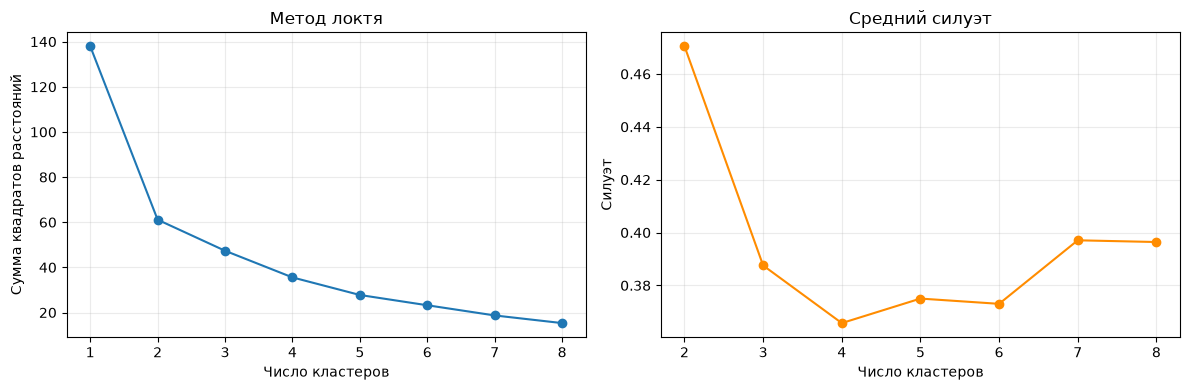

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Слева смотрим, насколько снижается inertia с каждым новым центром.
axes[0].plot(comparison["k"], comparison["inertia"], marker="o")
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("Число кластеров")
axes[0].set_ylabel("Сумма квадратов расстояний")
axes[0].set_xticks(comparison["k"])

# Справа сравниваем только те варианты, где силуэт определён.
valid = comparison.dropna(subset=["silhouette"])
axes[1].plot(valid["k"], valid["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Средний силуэт")
axes[1].set_xlabel("Число кластеров")
axes[1].set_ylabel("Силуэт")
axes[1].set_xticks(valid["k"])

for ax in axes:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

При переходе от одного к двум кластерам инерция снижается
со 138,00 до 61,12, примерно на 55,7%. Добавление третьего
центра снижает её до 47,36. На графике наиболее заметное
улучшение наблюдается при переходе к двум группам.

Средний силуэт максимален при k = 2 и составляет 0,4705.
При k = 3 он снижается до 0,3875. Для основной модели
выбираю два кластера.

## Итоговая модель и центры групп

После перебора осталось решение для восьми групп. Обучаю отдельную модель с двумя центрами. Возвращаю центры в исходные единицы для экономической интерпретации.

In [6]:
final_model, raw_labels = fit_kmeans(X_scaled, k=2)

# Каждая строка содержит средние координаты группы в исходных единицах.
centers = pd.DataFrame(
    scaler.inverse_transform(final_model.cluster_centers_),
    columns=features
)

# Присваиваем номер 1 группе с меньшей средней зарплатой.
order = centers["Salary"].sort_values().index
group_numbers = {old: new for new, old in enumerate(order, start=1)}
clustered = cities.copy()
clustered["Cluster"] = pd.Series(raw_labels).map(group_numbers).to_numpy()
centers = centers.rename(index=group_numbers).sort_index()
centers.index.name = "Cluster"
centers["Городов"] = clustered["Cluster"].value_counts()
display(centers[["Городов", *features]].round(2))

C:\Users\sergey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Городов,Work,Price,Salary
Cluster,,,,
1,21,1987.86,52.40,16.35
2,25,1789.24,84.97,59.03


## Сравнение разбиений на две и три группы

Проверю, как меняется состав кластеров при добавлении третьего
центра и по каким экономическим показателям различаются новые группы.

In [7]:
# Меняем только число центров. Данные и настройки обучения те же.
model_3, labels_3 = fit_kmeans(X_scaled, k=3)

# Сохраняем оба разбиения рядом для каждого города.
alternative = clustered.copy()
alternative["Cluster_3"] = labels_3 + 1

# Строка соответствует группе основной модели.
# Столбец соответствует группе модели с тремя центрами.
overlap = pd.crosstab(
    alternative["Cluster"],
    alternative["Cluster_3"],
    rownames=["Кластер при k = 2"],
    colnames=["Кластер при k = 3"]
)
display(overlap)

# Рассчитываем средние в исходных единицах для трёх групп.
profile_3 = alternative.groupby("Cluster_3").agg(
    Городов=("City", "size"),
    Work=("Work", "mean"),
    Price=("Price", "mean"),
    Salary=("Salary", "mean")
)
display(profile_3.round(2))

C:\Users\sergey\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Кластер при k = 3,1,2,3
Кластер при k = 2,,,
1,11,0,10
2,0,25,0


,Городов,Work,Price,Salary
Cluster_3,,,,
1,11,1855.45,50.78,16.59
2,25,1789.24,84.97,59.03
3,10,2133.50,54.17,16.08


При k = 3 группа из 25 городов сохраняется. Группа из 21 города
делится на две подгруппы из 10 и 11 городов. У них близкие средние
индексы зарплаты, а среднее число рабочих часов различается
примерно на 278 часов.

Третий кластер позволяет подробнее описать рабочую нагрузку
внутри одной группы. Для общей типологии сохраняю k = 2,
поскольку это разбиение имеет более высокий средний силуэт.

## Города и центры на плоскости

Каждая точка представляет город. По горизонтали показан индекс цен, по вертикали индекс зарплаты. Крестом обозначен центр каждой группы.

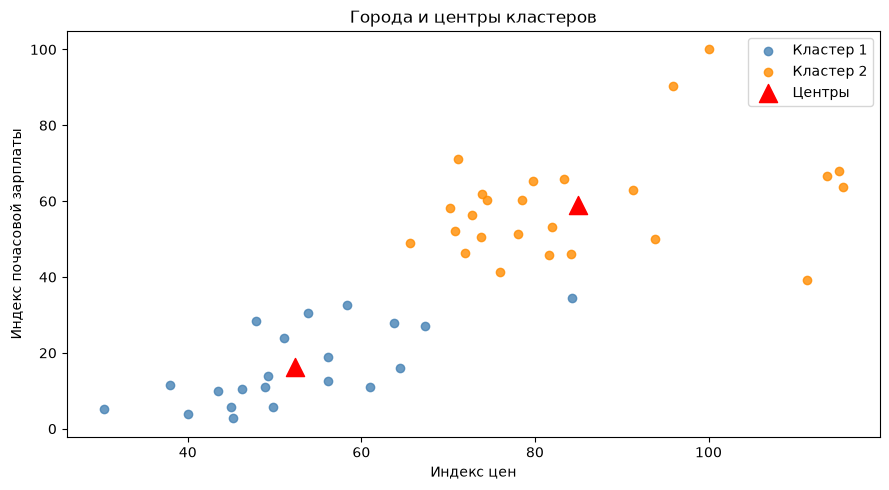

In [8]:
colors = {1: "steelblue", 2: "darkorange"}
fig, ax = plt.subplots(figsize=(9, 5))
for number, group in clustered.groupby("Cluster"):
    ax.scatter(group["Price"], group["Salary"], color=colors[number],
               alpha=0.8, label=f"Кластер {number}")

# Центры и города изображены в одинаковых единицах.
ax.scatter(centers["Price"], centers["Salary"], marker="^", s=170,
           color="red", label="Центры", zorder=3)
ax.set(xlabel="Индекс цен", ylabel="Индекс почасовой зарплаты",
       title="Города и центры кластеров")
ax.legend()
fig.tight_layout()
plt.show()

## Города в пространстве трёх признаков

Добавляю рабочие часы на вертикальную ось. Цвета соответствуют тем же кластерам, что и на плоском рисунке.

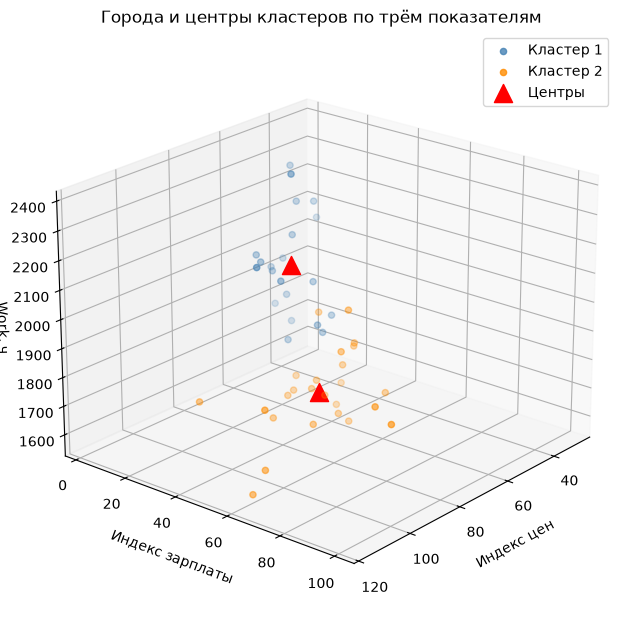

In [9]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
for number, group in clustered.groupby("Cluster"):
    ax.scatter(group["Price"], group["Salary"], group["Work"],
               color=colors[number], alpha=0.8, label=f"Кластер {number}")

ax.scatter(centers["Price"], centers["Salary"], centers["Work"],
           color="red", marker="^", s=170, label="Центры",
           depthshade=False)
ax.set_xlabel("Индекс цен", labelpad=7)
ax.set_ylabel("Индекс зарплаты", labelpad=7)
ax.set_zlabel("Work, ч", labelpad=3)
ax.set_title("Города и центры кластеров по трём показателям")
ax.view_init(elev=22, azim=40)
ax.legend()

# Оставляем поля для подписей трёхмерных осей.
fig.subplots_adjust(left=0.10, right=0.90, bottom=0.08, top=0.92)
plt.show()

## Разброс показателей внутри кластеров

Центры характеризуют средние значения групп. Чтобы оценить различия
между городами внутри каждой группы, сравню медианы и центральные
50% значений Work, Price и Salary.

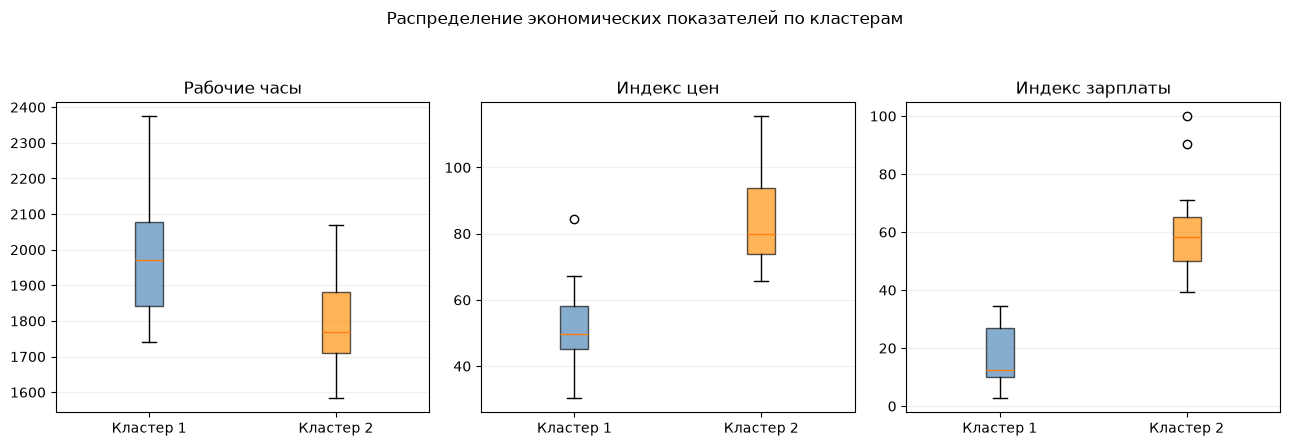

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

titles = {
    "Work": "Рабочие часы",
    "Price": "Индекс цен",
    "Salary": "Индекс зарплаты"
}

for ax, feature in zip(axes, features):
    # Берём исходные значения признака отдельно для каждой группы.
    group_1 = clustered.loc[clustered["Cluster"] == 1, feature]
    group_2 = clustered.loc[clustered["Cluster"] == 2, feature]

    # Линия внутри коробки показывает медиану.
    # Края коробки соответствуют первому и третьему квартилям.
    boxes = ax.boxplot([group_1, group_2], patch_artist=True)

    # Сохраняем цвета кластеров из диаграмм рассеяния.
    for box, group_number in zip(boxes["boxes"], [1, 2]):
        box.set_facecolor(colors[group_number])
        box.set_alpha(0.65)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Кластер 1", "Кластер 2"])
    ax.set_title(titles[feature])
    ax.grid(axis="y", alpha=0.2)

fig.suptitle("Распределение экономических показателей по кластерам")
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

Центральные 50% значений Salary у двух групп разделены.
По рабочим часам коробки перекрываются. Следовательно,
для типичных городов этих групп различие в оплате труда
выражено отчётливее, чем различие в рабочей нагрузке.

## Выводы

Метод KMeans выделил две группы среди 46 городов с полными данными.
Выбор k = 2 поддерживается наибольшим снижением инерции при переходе
от одного центра к двум и максимальным средним силуэтом 0,4705
среди проверенных разбиений.

Первая группа включает 21 город. Средние индексы цен и зарплаты
составляют 52,40 и 16,35, средний Work равен 1987,86 часа.
Во второй группе 25 городов. Средние индексы выше и составляют
84,97 и 59,03, а средний Work ниже и равен 1789,24 часа.

При добавлении третьего центра первая группа разделяется
преимущественно по рабочим часам, вторая сохраняется.
Для описания основных различий в этой выборке за 1991 год
выбрано разбиение на две группы.